In [1]:
import os
import numpy as np
import scipy.io as sio
from tqdm import tqdm
import h5py

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt

import sys
sys.path.append("..") 

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print(device)

cuda


In [ ]:
from processing import  load_UCI_dataset, plot_regression_results, print_metrics, evaluate_convtran_vitaldb
from UCI.pre_processing import  create_dataloaders

BASE_DIR = "/data1/yashvi_bhuva/BP_estimation_using_PPG/VitalDB/ML/non_fiducial_features/8sec_0overlap/vitaldb_checkpoints"

In [3]:
X_train, y_train, X_val, y_val, X_test, y_test = load_UCI_dataset(WINDOW_SIZE= 1000, STEP_SIZE= 1000)

Total recordings: 12000
Train recordings: 9600
Validation recordings: 1200
Test recordings: 1200


100%|██████████| 9600/9600 [01:21<00:00, 118.16it/s]


Skipped recordings: 107


100%|██████████| 1200/1200 [00:10<00:00, 112.85it/s]


Skipped recordings: 8


100%|██████████| 1200/1200 [00:10<00:00, 113.13it/s]


Skipped recordings: 9


In [4]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

# The shape should be : (batch, channels, length), length = 8*125 = 1000samples, only one channel as PPG and 

X_train: (263103, 1, 1000)
y_train: (263103, 2)
X_val: (33223, 1, 1000)
y_val: (33223, 2)
X_test: (33347, 1, 1000)
y_test: (33347, 2)


In [5]:
print(X_train.dtype)
print(y_train.dtype)


float32
float32


In [6]:
cat ConvTran/Models/model.py

import numpy as np
from torch import nn
from Models.AbsolutePositionalEncoding import tAPE, AbsolutePositionalEncoding, LearnablePositionalEncoding
from Models.Attention import Attention, Attention_Rel_Scl, Attention_Rel_Vec


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


class Permute(nn.Module):
    def forward(self, x):
        return x.permute(1, 0, 2)


def model_factory(config):
    if config['Net_Type'][0] == 'T':
        model = Transformer(config, output_size=config['output_size'])
    elif config['Net_Type'][0] == 'CC-T':
        model = CasualConvTran(config, output_size=config['output_size'])
    else:
        model = ConvTran(config, output_size=config['output_size'])
    return model


class Transformer(nn.Module):
    def __init__(self, config, output_size):
        super().__init__()
        # Parameters Initialization -----------------------------------------------
        channel_size, seq_len = config['Data_sh

In [7]:
train_loader, val_loader, test_loader = create_dataloaders(
    X_train,
    y_train,
    X_val,
    y_val,
    X_test,
    y_test,
    batch_size=64
)

X_batch, y_batch = next(iter(train_loader))

print("X:", X_batch.shape, X_batch.dtype)
print("y:", y_batch.shape, y_batch.dtype)

X: torch.Size([64, 1, 1000]) torch.float32
y: torch.Size([64, 2]) torch.float32


In [8]:
config = {
    # Input
    'Data_shape': (32, 1, 1000),

    # ConvTran architecture
    'emb_size': 16,
    'num_heads': 8,
    'dim_ff': 256,

    # Positional encoding
    'Fix_pos_encode': 'tAPE',
    'Rel_pos_encode': 'eRPE',

    # Dropout
    'dropout': 0.01,

    # Regression
    'output_size': 2,

    # Model type
    'Net_Type': ['C-T'],
}

In [9]:
import sys

sys.path.insert(
    0,
    "/data1/yashvi_bhuva/BP_estimation_using_PPG/ConvTran/ConvTran"
)
from Models.model import model_factory
model = model_factory(config)

X_batch, y_batch = next(iter(train_loader))

output = model(X_batch)

print("Input :", X_batch.shape)
print("Output:", output.shape)

Input : torch.Size([64, 1, 1000])
Output: torch.Size([64, 2])


In [10]:
import torch.nn as nn

criterion = nn.SmoothL1Loss()

loss = criterion(output, y_batch)

print("Prediction shape:", output.shape)
print("Target shape:", y_batch.shape)
print("Loss:", loss.item())

loss.backward()

print("Backward pass successful")

Prediction shape: torch.Size([64, 2])
Target shape: torch.Size([64, 2])
Loss: 99.34900665283203
Backward pass successful


In [11]:
from torch.optim import AdamW

optimizer = AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

optimizer.step()

print("Optimizer step successful")

Optimizer step successful


In [12]:
model.train()

X_batch, y_batch = next(iter(train_loader))

optimizer.zero_grad()

pred = model(X_batch)

loss = criterion(pred, y_batch)

loss.backward()

optimizer.step()

print("Loss:", loss.item())
print("Training step successful")

Loss: 100.19793701171875
Training step successful


In [13]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = model_factory(config).to(device)

In [14]:
loss_module = torch.nn.SmoothL1Loss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

In [15]:
from Training import SupervisedTrainer, validate, train_runner
trainer = SupervisedTrainer(
    model=model,
    dataloader=train_loader,
    device=device,
    loss_module=loss_module,
    optimizer=optimizer,
    l2_reg=None
)

val_evaluator = SupervisedTrainer(
    model=model,
    dataloader=val_loader,
    device=device,
    loss_module=loss_module,
    optimizer=None,
    l2_reg=None
)

In [16]:
import os

config['optimizer'] = optimizer
config['loss_module'] = loss_module
config['patience'] = 10
config['key_metric'] = 'loss'
config['save_dir'] = './checkpoints'

os.makedirs(config['save_dir'], exist_ok=True)

In [22]:
config['epochs'] = 50

train_runner(
    config=config,
    model=model,
    trainer=trainer,
    val_evaluator=val_evaluator,
    path='./checkpoints/best_model.pth'
)

Training Epoch:   0%|          | 0/50 [00:00<?, ?it/s]2026-10-11 13:31:34,368 | INFO : Validation Summary: epoch: 1.000000 | loss: 55.540026 | SBP_MAE: 87.814857 | DBP_MAE: 24.265200 | SBP_RMSE: 90.657448 | DBP_RMSE: 26.686333 | 



Best validation loss: 55.54002625812411
Saving best model for epoch: 1



2026-10-11 13:31:34,584 | INFO : Epoch 1 Training Summary: epoch: 1.000000 | loss: 68.947301 | SBP_MAE: 101.559250 | DBP_MAE: 37.335342 | SBP_RMSE: 104.185715 | DBP_RMSE: 39.604477 | 
Training Epoch:   2%|▏         | 1/50 [07:32<6:09:45, 452.77s/it]2026-10-11 13:39:11,294 | INFO : Validation Summary: epoch: 2.000000 | loss: 28.846272 | SBP_MAE: 50.200523 | DBP_MAE: 8.480037 | SBP_RMSE: 55.016525 | DBP_RMSE: 11.090000 | 
2026-10-11 13:39:11,383 | INFO : Epoch 2 Training Summary: epoch: 2.000000 | loss: 40.389745 | SBP_MAE: 69.824028 | DBP_MAE: 11.945569 | SBP_RMSE: 74.050171 | DBP_RMSE: 15.863842 | 
Training Epoch:   4%|▍         | 2/50 [15:09<6:04:06, 455.14s/it]


Best validation loss: 28.846271551864934
Saving best model for epoch: 2



2026-10-11 13:54:02,616 | INFO : Validation Summary: epoch: 3.000000 | loss: 13.372247 | SBP_MAE: 19.362070 | DBP_MAE: 8.363998 | SBP_RMSE: 25.052649 | DBP_RMSE: 11.201560 | 
2026-10-11 13:54:02,736 | INFO : Epoch 3 Training Summary: epoch: 3.000000 | loss: 19.231922 | SBP_MAE: 31.332726 | DBP_MAE: 8.114777 | SBP_RMSE: 38.326435 | DBP_RMSE: 10.802584 | 
Training Epoch:   6%|▌         | 3/50 [30:00<8:32:33, 654.32s/it]

...

2026-10-11 14:23:55,125 | INFO : Validation Summary: epoch: 5.000000 | loss: 11.453387 | SBP_MAE: 16.006666 | DBP_MAE: 7.875982 | SBP_RMSE: 20.727528 | DBP_RMSE: 11.047436 | 
2026-10-11 14:23:55,239 | INFO : Epoch 5 Training Summary: epoch: 5.000000 | loss: 11.128069 | SBP_MAE: 15.731638 | DBP_MAE: 7.500763 | SBP_RMSE: 20.110748 | DBP_RMSE: 10.373322 | 
Training Epoch:  10%|█         | 5/50 [59:53<9:59:54, 799.89s/it]


Best validation loss: 11.45338732556921
Saving best model for epoch: 5



2026-10-11 14:41:34,873 | INFO : Validation Summary: epoch: 6.000000 | loss: 10.915090 | SBP_MAE: 15.298482 | DBP_MAE: 7.508288 | SBP_RMSE: 19.752165 | DBP_RMSE: 10.477725 | 
2026-10-11 14:41:34,949 | INFO : Epoch 6 Training Summary: epoch: 6.000000 | loss: 10.678775 | SBP_MAE: 15.063712 | DBP_MAE: 7.268610 | SBP_RMSE: 19.360538 | DBP_RMSE: 10.120526 | 
Training Epoch:  12%|█▏        | 6/50 [1:17:33<10:51:21, 888.23s/it]


Best validation loss: 10.915090387533413
Saving best model for epoch: 6



KeyboardInterrupt: 

In [ ]:
checkpoint = torch.load(
    './checkpoints/model_best.pth',
    map_location=device
)

model.load_state_dict(checkpoint['state_dict'])
model.to(device)

test_evaluator = SupervisedTrainer(
    model=model,
    dataloader=test_loader,
    device=device,
    loss_module=loss_module,
    optimizer=None,
    l2_reg=None,
    print_interval=10,
    console=True,
    print_conf_mat=False
)

In [ ]:
test_metrics, test_results = test_evaluator.evaluate(
    epoch_num=None,
    keep_all=True
)

In [ ]:
y_true = test_results['targets']
y_pred = test_results['predictions']

print("True shape:", y_true.shape)
print("Pred shape:", y_pred.shape)

True shape: (33347, 2)
Pred shape: (33347, 2)


===== SBP Metrics =====
RMSE: 117.5069
MSE : 13807.8740
R²  : -25.1441
MAE : 115.2377


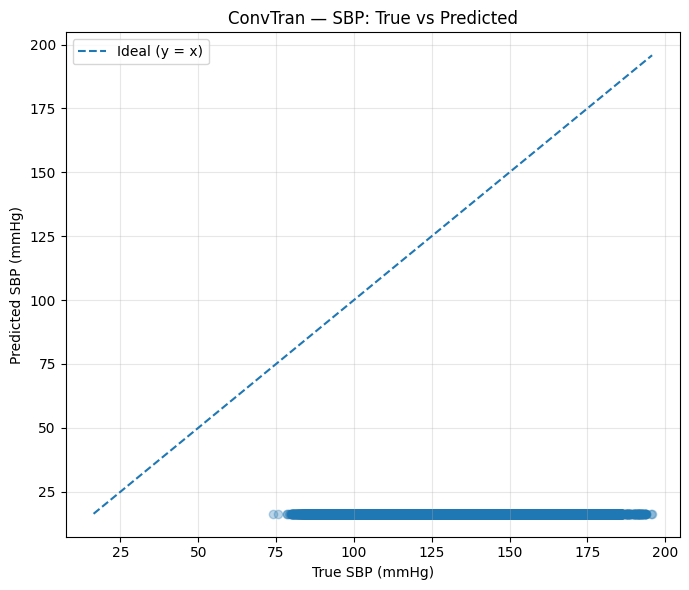

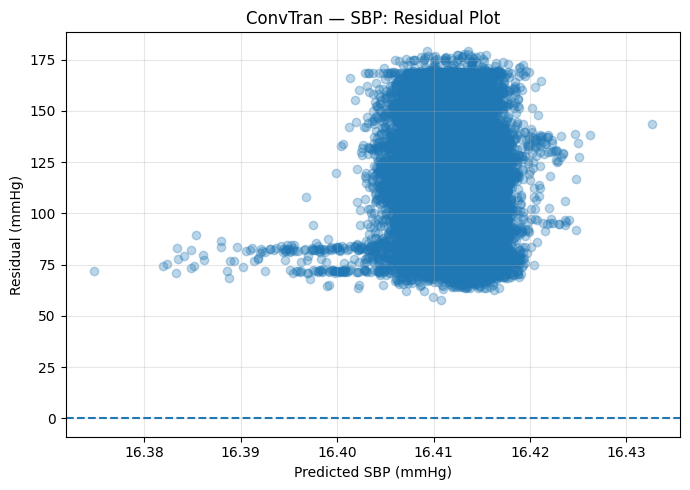

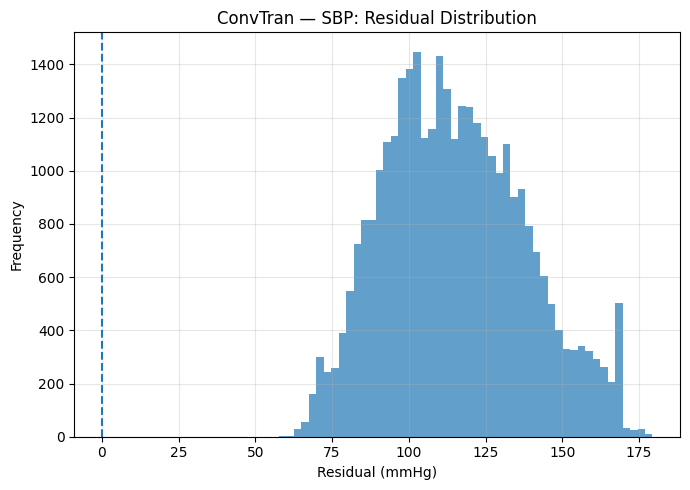

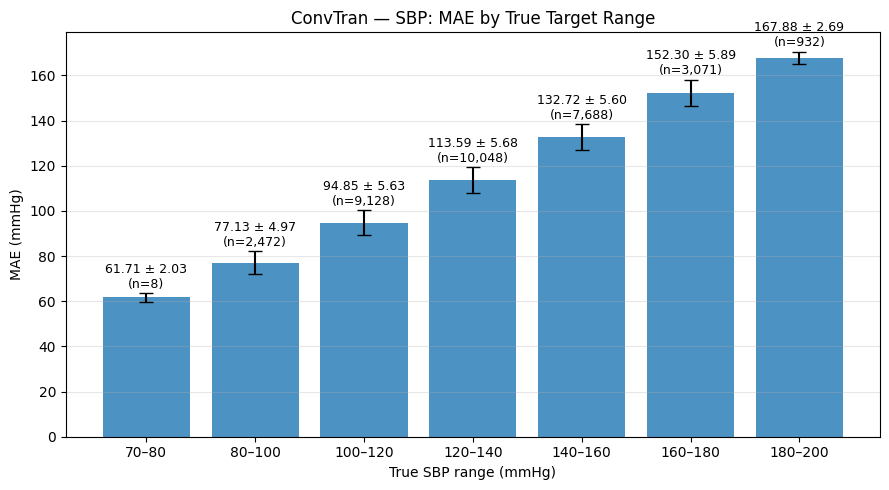

===== DBP Metrics =====
RMSE: 51.3700
MSE : 2638.8811
R²  : -20.1242
MAE : 50.1393


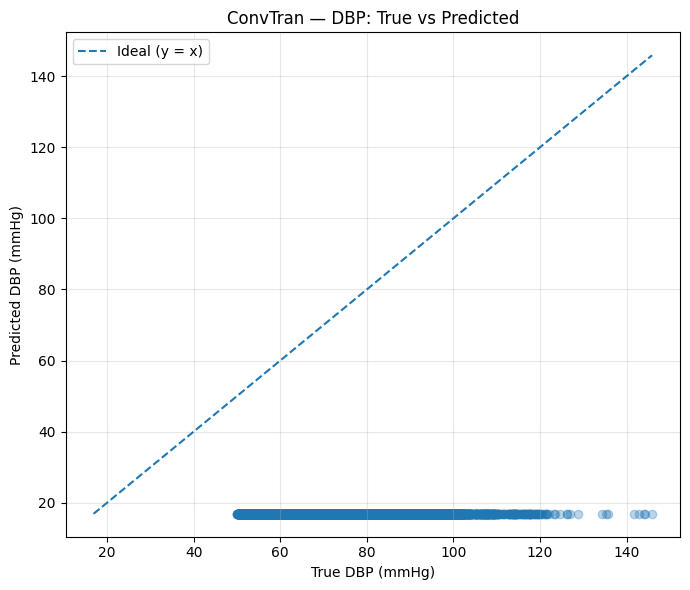

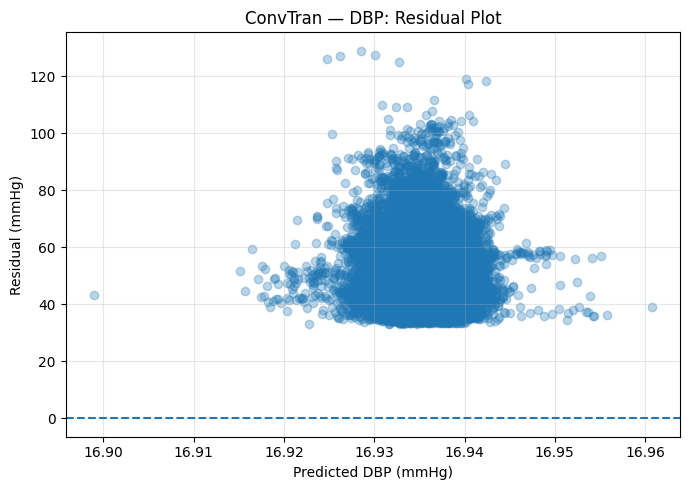

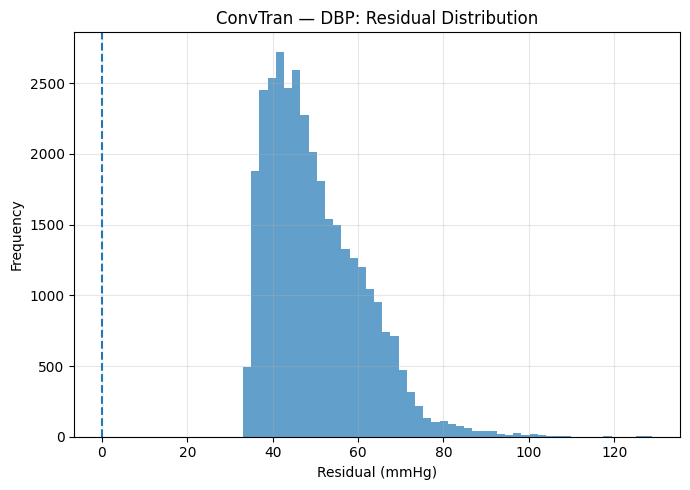

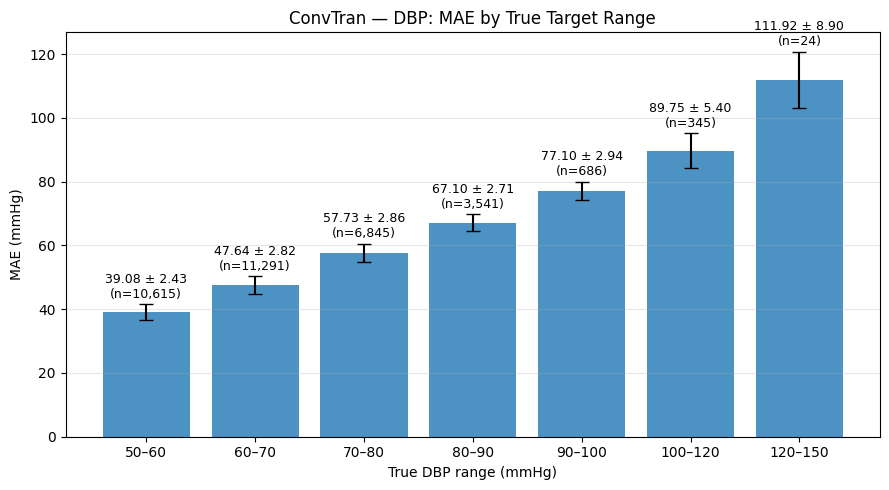

In [ ]:
# Convert to NumPy arrays if they are PyTorch tensors
if torch.is_tensor(y_true):
    y_true = y_true.detach().cpu().numpy()

if torch.is_tensor(y_pred):
    y_pred = y_pred.detach().cpu().numpy()

# Extract SBP and DBP separately
sbp_true = y_true[:, 0]
sbp_pred = y_pred[:, 0]

dbp_true = y_true[:, 1]
dbp_pred = y_pred[:, 1]

# SBP metrics and plots
print("===== SBP Metrics =====")
print_metrics(sbp_true, sbp_pred)

plot_regression_results(
    sbp_true,
    sbp_pred,
    model_name="ConvTran",
    target_name="SBP"
)

# DBP metrics and plots
print("===== DBP Metrics =====")
print_metrics(dbp_true, dbp_pred)

plot_regression_results(
    dbp_true,
    dbp_pred,
    model_name="ConvTran",
    target_name="DBP"
)

In [ ]:
BASE_DIR = "/data1/yashvi_bhuva/BP_estimation_using_PPG/VitalDB/ML/non_fiducial_features/8sec_0overlap/vitaldb_checkpoints"
checkpoint = torch.load(
    './checkpoints/best_model.pth',
    map_location=device
)

model.load_state_dict(checkpoint['state_dict'])
model.to(device)
model.eval()

convtran_vitaldb_results = evaluate_convtran_vitaldb(
    model=model,  # Your trained, best-checkpoint ConvTran model
    base_dir=BASE_DIR,
    batch_size=64,
    device=device
)